<a href="https://colab.research.google.com/github/rgmithraa30/student-performance-prediction/blob/main/student_performance_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:

!wget -q https://archive.ics.uci.edu/static/public/320/student+performance.zip
!unzip -o student+performance.zip
!unzip -o student.zip
import pandas as pd
df = pd.read_csv("student-mat.csv", sep=";")
df.head()
df.info()
print(df.shape)
print(df.isnull().sum().sum())   # total missing values
print(df.duplicated().sum())     # duplicate rows
df.describe()
print(df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Archive:  student+performance.zip
 extracting: .student.zip_old        
 extracting: student.zip             
Archive:  student.zip
  inflating: student-mat.csv         
  inflating: student-por.csv         
  inflating: student-merge.R         
  inflating: student.txt             
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studyt

In [5]:
print(df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.describe()

(395, 33)
Missing values: 0
Duplicate rows: 0


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


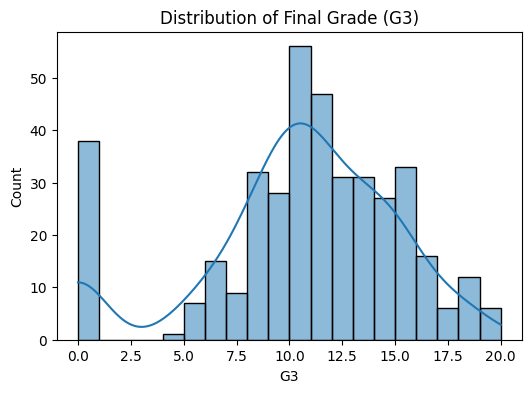

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))
sns.histplot(df["G3"], bins=20, kde=True)
plt.title("Distribution of Final Grade (G3)")
plt.show()

In [7]:
corr = df.corr(numeric_only=True)["G3"].sort_values(ascending=False)
print(corr)

G3            1.000000
G2            0.904868
G1            0.801468
Medu          0.217147
Fedu          0.152457
studytime     0.097820
famrel        0.051363
absences      0.034247
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64


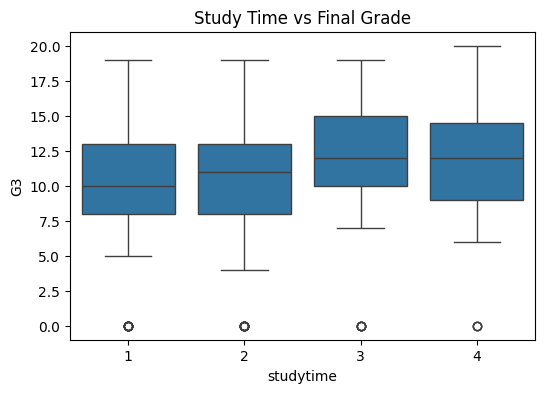

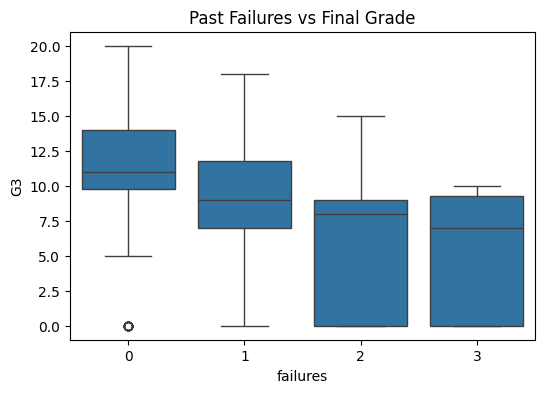

In [8]:
plt.figure(figsize=(6,4))
sns.boxplot(x="studytime", y="G3", data=df)
plt.title("Study Time vs Final Grade")
plt.show()

plt.figure(figsize=(6,4))
sns.boxplot(x="failures", y="G3", data=df)
plt.title("Past Failures vs Final Grade")
plt.show()

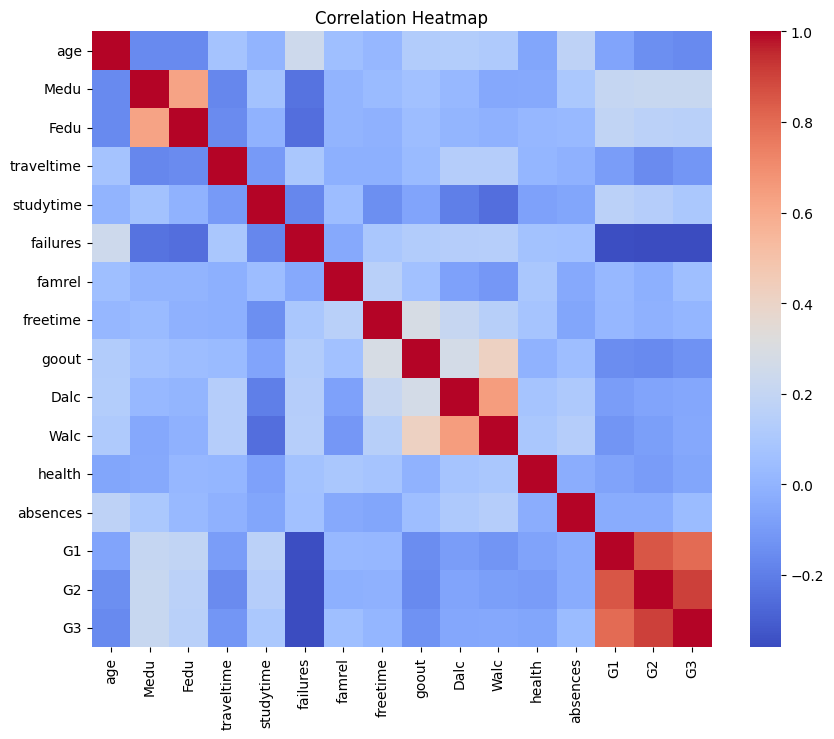

In [9]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [10]:
df_model = pd.get_dummies(df, drop_first=True)

y = df_model["G3"]
X = df_model.drop(columns=["G3", "G1", "G2"])
print(X.shape)

(395, 39)


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

(316, 39) (79, 39)


In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name)
    print("  R2  :", round(r2_score(y_test, pred), 3))
    print("  MAE :", round(mean_absolute_error(y_test, pred), 3))
    print("  RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))

Linear Regression
  R2  : 0.141
  MAE : 3.395
  RMSE: 4.196
Random Forest
  R2  : 0.245
  MAE : 3.148
  RMSE: 3.935


In [13]:
# Model with G1 and G2 included
X2 = df_model.drop(columns=["G3"])
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42
)

rf2 = RandomForestRegressor(n_estimators=100, random_state=42)
rf2.fit(X2_train, y2_train)
pred2 = rf2.predict(X2_test)

print("Random Forest with G1 and G2")
print("  R2  :", round(r2_score(y2_test, pred2), 3))
print("  MAE :", round(mean_absolute_error(y2_test, pred2), 3))
print("  RMSE:", round(np.sqrt(mean_squared_error(y2_test, pred2)), 3))

Random Forest with G1 and G2
  R2  : 0.815
  MAE : 1.165
  RMSE: 1.949


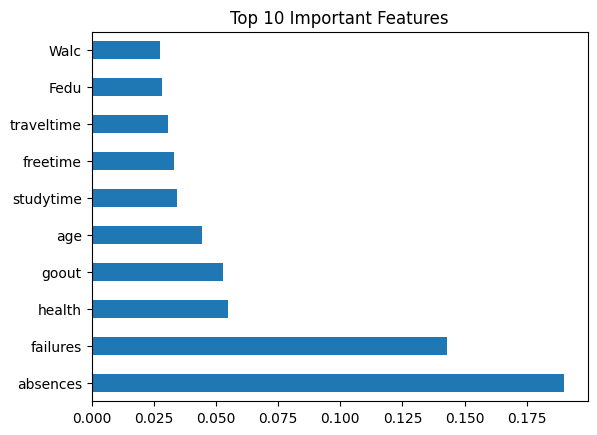

In [14]:
importances = pd.Series(models["Random Forest"].feature_importances_, index=X.columns)
importances.sort_values(ascending=False).head(10).plot(kind="barh")
plt.title("Top 10 Important Features")
plt.show()

In [15]:
def predict_grade(**inputs):
    row = X_train.median().to_frame().T   # start with typical values
    for col, value in inputs.items():
        row[col] = value
    grade = models["Random Forest"].predict(row)[0]
    return round(grade, 1)

g = predict_grade(studytime=3, failures=0, absences=2, age=17)
print("Predicted final grade:", g, "/ 20")
print("Result:", "Pass" if g >= 10 else "At risk")

Predicted final grade: 11.5 / 20
Result: Pass


In [16]:
g = predict_grade(studytime=1, failures=2, absences=15, age=19)
print("Predicted final grade:", g, "/ 20")
print("Result:", "Pass" if g >= 10 else "At risk")

Predicted final grade: 9.0 / 20
Result: At risk


student_performance_prediction.ipynb